# Eyeris — Khám phá bộ sưu tập ảnh

Notebook độc lập này phân tích tám phần: **Tổng quan, Dung lượng, Kích thước ảnh,
Tỷ lệ khung hình, Màu sắc, Tags, Rating và Thời gian**.
Mục tiêu là hiểu bộ sưu tập và đưa ra gợi ý quản lý có căn cứ, không đánh giá chất lượng nghệ thuật của ảnh.

**Cách chạy:** chọn kernel Python có `pandas`, `numpy`, `matplotlib`, `seaborn`, `Pillow`,
sau đó **Restart Kernel → Run All**. Chỉ cần đổi `COLLECTION_PATH` trong ô cấu hình khi chuyển máy.
Không cần tải mô hình AI, cài ChromaDB hay truy cập Internet.

**Nguồn dữ liệu:** `index.db` cung cấp metadata; `images/` cung cấp bản ảnh và thumbnail;
`embeddings/` được kiểm tra dung lượng và độ bao phủ ID thông qua SQLite của Chroma.
Mọi database đều mở ở chế độ chỉ đọc. Notebook không sửa hay xóa dữ liệu nguồn.
Độ bao phủ ID không chứng minh vector đầy đủ, đúng mô hình hoặc tìm kiếm chính xác.

In [ ]:
from pathlib import Path
from collections import Counter
from itertools import combinations
import colorsys
import sqlite3
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from matplotlib.ticker import MaxNLocator
import seaborn as sns
from PIL import Image, ImageOps
from IPython.display import display, Markdown

COLLECTION_PATH = Path(r"C:\Users\admin\OneDrive\Hình ảnh\Test")
LOCAL_TIMEZONE = "Asia/Ho_Chi_Minh"
TOP_N = 15
MAX_GALLERY = 8
SQUARE_TOLERANCE = 0.02  # tỷ lệ 0.98–1.02 được coi gần vuông
RUN_AT = pd.Timestamp.now(tz=LOCAL_TIMEZONE)

sns.set_theme(style="whitegrid", palette="Set2", font="DejaVu Sans")
plt.rcParams.update({"figure.figsize": (11, 5), "axes.titlesize": 14,
                     "axes.labelsize": 11, "figure.dpi": 110})
pd.set_option("display.max_columns", 24)
pd.set_option("display.max_colwidth", 70)

def note(text):
    display(Markdown(text))

def finish(fig):
    fig.tight_layout()
    plt.show()
    plt.close(fig)

def horizontal(series, title, xlabel="Số ảnh", colors=None):
    series = series.sort_values()
    if series.empty:
        note(f"**{title}:** không có dữ liệu phù hợp.")
        return
    fig, ax = plt.subplots(figsize=(10, max(3, len(series) * 0.35)))
    bars = ax.barh(series.index.astype(str), series.values, color=colors)
    ax.bar_label(bars, fmt="%.2f" if series.dtype.kind == "f" else "%d", padding=3)
    ax.set(title=title, xlabel=xlabel)
    ax.margins(x=0.18)
    finish(fig)

def safe_file(root, *parts):
    # Không cho đường dẫn trong database thoát khỏi thư mục dataset.
    root = root.resolve()
    path = root.joinpath(*map(str, parts)).resolve()
    return path if path.is_relative_to(root) else None

def gallery(rows, title, caption="fullname", limit=MAX_GALLERY):
    rows = rows.head(limit)
    if rows.empty:
        note(f"**{title}:** không có ảnh phù hợp.")
        return
    fig, axes = plt.subplots(math.ceil(len(rows) / 4), 4,
                             figsize=(14, 3.4 * math.ceil(len(rows) / 4)), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, row) in zip(axes.flat, rows.iterrows()):
        path = row["thumbnail_path"] if row["thumbnail_exists"] else row["image_path"]
        try:
            if path is None:
                raise ValueError("Đường dẫn không hợp lệ")
            with Image.open(path) as im:
                preview = ImageOps.exif_transpose(im).convert("RGB")
                preview.thumbnail((420, 300))
                ax.imshow(preview)
        except (OSError, ValueError) as exc:
            ax.text(0.5, 0.5, f"Không đọc được ảnh\n{type(exc).__name__}", ha="center")
        ax.set_title(f"ID {row['id']} · {str(row[caption])[:45]}\n"
                     f"{row['width']:g}×{row['height']:g} · {row['size_mib']:.2f} MiB", fontsize=9)
    fig.suptitle(title, y=1.02)
    finish(fig)

## Chuẩn bị dữ liệu
Đọc nguyên trạng bảng `images`, chuẩn hóa vào bản sao và tạo thuộc tính phân tích.
`MiB = bytes / 1024²`; megapixel dùng một triệu pixel. Chỉ dùng kích thước/dung lượng hợp lệ
cho các phép tính tương ứng. Tags được tách bằng `|`, loại trùng trong mỗi ảnh và giữ nguyên cách viết.
Không gộp tags khác nhau chỉ vì khác chữ hoa/chữ thường.

`created`/`modified` là timestamp **file**, không phải ngày chụp hoặc ngày nhập Collection.
Rating 0 là **chưa đánh giá**. Độ sáng và nhóm màu bên dưới mô tả **màu chủ đạo**, không phải toàn bộ pixel ảnh.

In [ ]:
db_path = COLLECTION_PATH / "index.db"
if not db_path.is_file():
    raise FileNotFoundError(f"Không tìm thấy {db_path}. Hãy sửa COLLECTION_PATH.")
with sqlite3.connect(db_path.resolve().as_uri() + "?mode=ro", uri=True) as conn:
    raw = pd.read_sql_query("SELECT * FROM images", conn)
required = {"id", "hash", "fullname", "format", "size", "width", "height",
            "created", "modified", "rating", "tags", "color_1"}
missing = required - set(raw.columns)
if missing:
    raise ValueError(f"Schema thiếu cột: {sorted(missing)}")
if raw.empty:
    raise ValueError("Collection chưa có ảnh; hãy nhập ảnh rồi chạy lại notebook.")
df = raw.copy()
numeric = ["size", "width", "height", "created", "modified", "rating"]
for col in numeric:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["format"] = df["format"].fillna("UNKNOWN").astype(str).str.strip().str.upper().replace({"JPEG": "JPG", "": "UNKNOWN"})
df["valid_dimensions"] = df["width"].gt(0) & df["height"].gt(0) & np.isfinite(df[["width", "height"]]).all(axis=1)
df["size_mib"] = df["size"].where(df["size"].ge(0) & np.isfinite(df["size"])) / 1024**2
df["megapixels"] = (df["width"] * df["height"] / 1e6).where(df["valid_dimensions"])
df["aspect_ratio"] = (df["width"] / df["height"]).where(df["valid_dimensions"])
df["bytes_per_pixel"] = df["size"].where(df["size"].ge(0)) / (df["megapixels"] * 1e6)
df["orientation"] = np.select(
    [~df["valid_dimensions"], df["aspect_ratio"].between(1-SQUARE_TOLERANCE, 1+SQUARE_TOLERANCE), df["aspect_ratio"].gt(1)],
    ["Không hợp lệ", "Gần vuông", "Ngang"], default="Dọc")
def split_tags(value):
    if pd.isna(value):
        return []
    return list(dict.fromkeys(t.strip() for t in str(value).split("|") if t.strip()))
df["tag_list"] = df["tags"].map(split_tags)
df["tag_count"] = df["tag_list"].map(len)
df["has_tags"] = df["tag_count"].gt(0)
df["is_rated"] = df["rating"].isin([1, 2, 3, 4, 5])
for col in ["created", "modified"]:
    df[col + "_datetime"] = pd.to_datetime(df[col].where(df[col].gt(0)), unit="ms", errors="coerce", utc=True).dt.tz_convert(LOCAL_TIMEZONE)
df["image_path"] = [safe_file(COLLECTION_PATH / "images", h, n) for h, n in zip(df["hash"], df["fullname"])]
df["thumbnail_path"] = [safe_file(COLLECTION_PATH / "images", h, "thumbnail.png") for h in df["hash"]]
df["image_exists"] = df["image_path"].map(lambda p: p is not None and p.is_file())
df["thumbnail_exists"] = df["thumbnail_path"].map(lambda p: p is not None and p.is_file())
note(f"Đã đọc **{len(df):,} ảnh**. Thời điểm phân tích: **{RUN_AT:%Y-%m-%d %H:%M %Z}**.")
display(df[["id", "fullname", "format", "size_mib", "width", "height", "tag_count", "rating"]].head())

Đã đọc **101 ảnh**. Thời điểm phân tích: **2026-11-10 22:14 +07**.

,id,fullname,format,size_mib,width,height,tag_count,rating
0,1,012.webp,WEBP,8.041712,3840,2160,1,0
1,2,voxel-houses-monochrome.webp,WEBP,1.713182,3840,2160,1,0
2,3,house_garden.webp,WEBP,0.461319,3840,2160,1,0
3,4,macos-sonoma-wallpapers-5120x2160-v0-q59obfq8h5wb1.webp,WEBP,4.840403,5120,2160,1,0
4,5,dream-river-4k.webp,WEBP,6.840666,3840,2160,1,0


## 1. Tổng quan
**Câu hỏi:** Collection lớn đến đâu, dữ liệu có đủ để phân tích không, và ảnh đã được lập embedding đến mức nào?
Dung lượng file hiện tại được đối chiếu với dung lượng metadata; hai số có thể khác sau khi sửa XMP.
Kiểm tra tồn tại file không thay thế kiểm tra giải mã toàn bộ ảnh.

,Giá trị
Số ảnh trong SQLite,101.00
Số định dạng,3.00
Dung lượng ảnh theo metadata (MiB),502.99
Median dung lượng (MiB),3.45
Ảnh có tags (%),74.30
Ảnh đã đánh giá (%),0.00
Ảnh gốc tồn tại (%),100.00
Thumbnail tồn tại (%),100.00


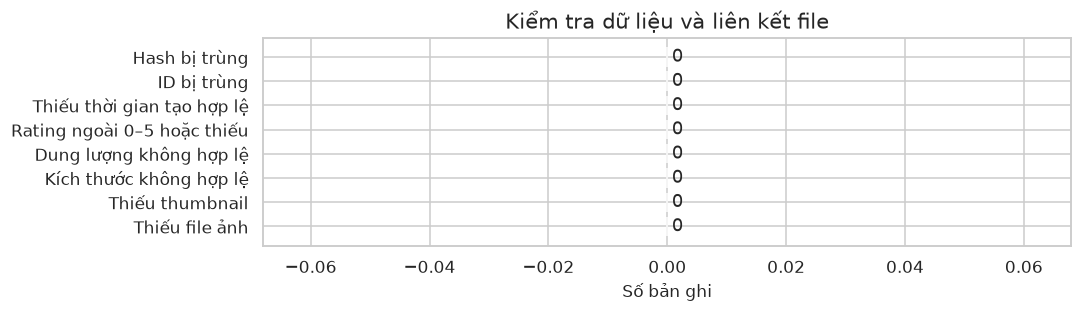

,images,total_mib,median_mib,median_mp
format,,,,
WEBP,70,399.76,6.61,8.29
PNG,26,93.02,0.65,4.02
JPG,5,10.21,1.21,14.17


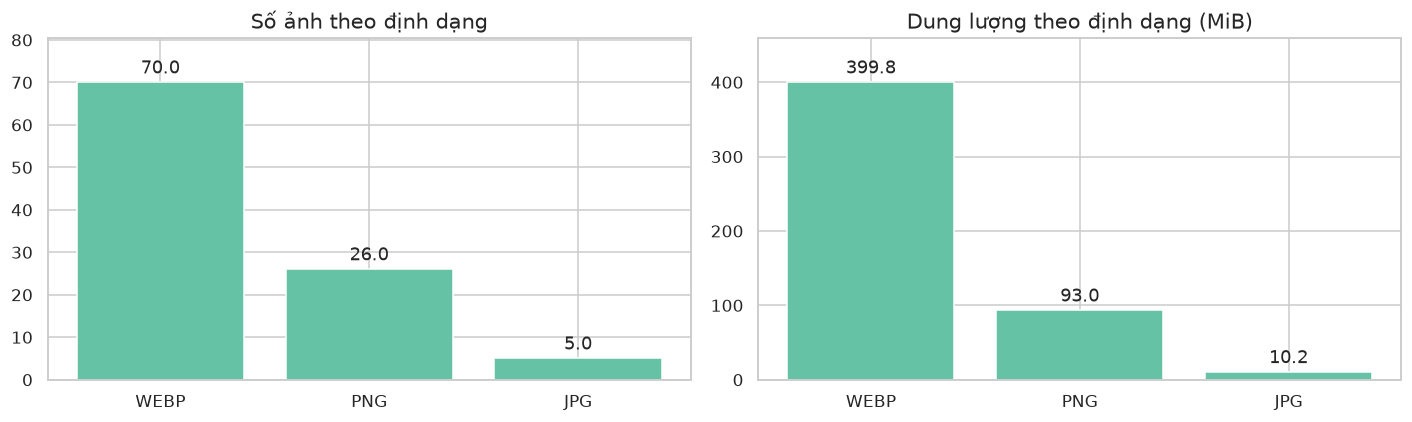

,Thành phần,Số file,MiB thực tế
0,index.db,1,0.05
1,images,205,523.47
2,embeddings,5,0.80


,id,name,dimension
0,e3bfcfd9-40b0-4c38-9e1d-43c4d2821ec8,images,512


,Số lượng
ID khớp với ảnh,101
Ảnh chưa có bản ghi embedding,0
ID embedding không khớp ảnh,0


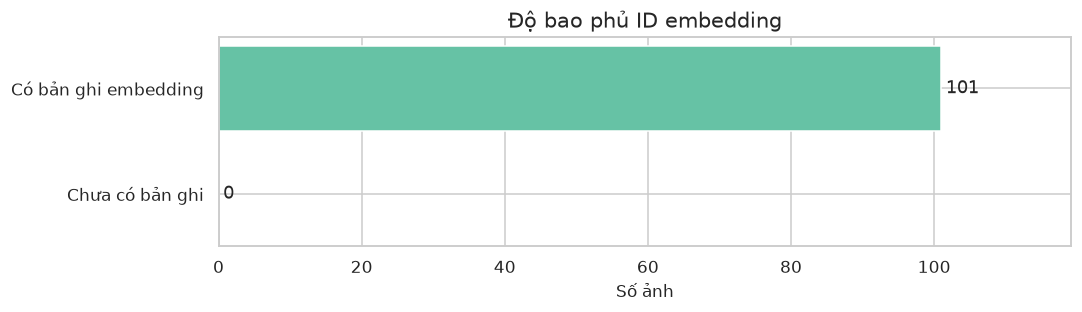

Kiểm tra dựa trên ID chuỗi của bảng images trong Chroma; không đọc vector HNSW, không đánh giá độ đúng của tìm kiếm.

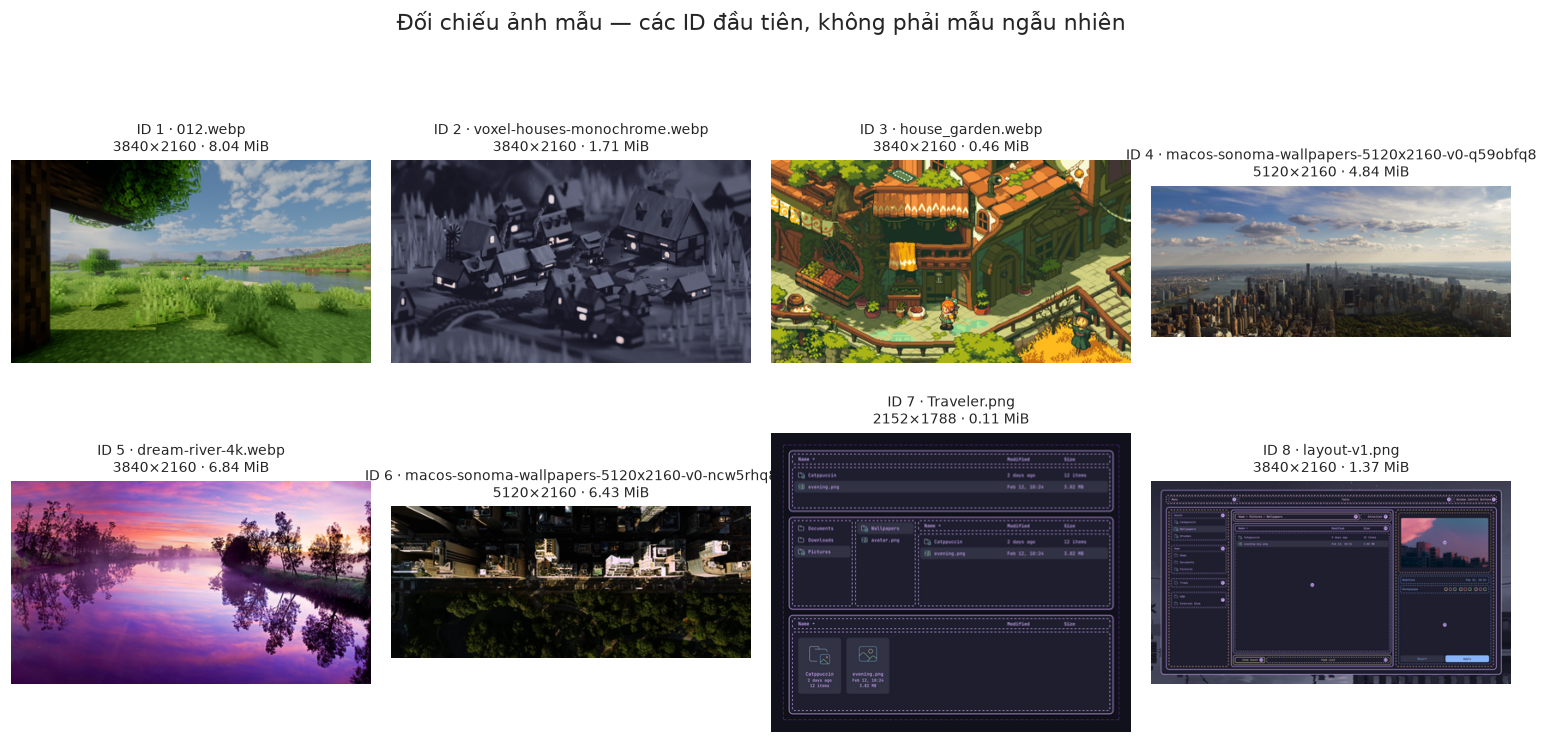

In [ ]:
summary = pd.Series({
    "Số ảnh trong SQLite": len(df), "Số định dạng": df["format"].nunique(),
    "Dung lượng ảnh theo metadata (MiB)": round(df["size_mib"].sum(), 2),
    "Median dung lượng (MiB)": round(df["size_mib"].median(), 2),
    "Ảnh có tags (%)": round(df["has_tags"].mean()*100, 1),
    "Ảnh đã đánh giá (%)": round(df["is_rated"].mean()*100, 1),
    "Ảnh gốc tồn tại (%)": round(df["image_exists"].mean()*100, 1),
    "Thumbnail tồn tại (%)": round(df["thumbnail_exists"].mean()*100, 1),
})
display(summary.to_frame("Giá trị"))
quality = pd.Series({"Thiếu file ảnh": (~df["image_exists"]).sum(),
                     "Thiếu thumbnail": (~df["thumbnail_exists"]).sum(),
                     "Kích thước không hợp lệ": (~df["valid_dimensions"]).sum(),
                     "Dung lượng không hợp lệ": df["size_mib"].isna().sum(),
                     "Rating ngoài 0–5 hoặc thiếu": (~df["rating"].isin(range(6))).sum(),
                     "Thiếu thời gian tạo hợp lệ": df["created_datetime"].isna().sum(),
                     "ID bị trùng": df["id"].duplicated().sum(),
                     "Hash bị trùng": df["hash"].duplicated().sum()})
horizontal(quality, "Kiểm tra dữ liệu và liên kết file", "Số bản ghi")
format_summary = df.groupby("format").agg(images=("id", "size"), total_mib=("size_mib", "sum"),
    median_mib=("size_mib", "median"), median_mp=("megapixels", "median")).sort_values("total_mib", ascending=False)
display(format_summary.round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, title in zip(axes, ["images", "total_mib"], ["Số ảnh theo định dạng", "Dung lượng theo định dạng (MiB)"]):
    bars = ax.bar(format_summary.index, format_summary[col])
    ax.bar_label(bars, fmt="%.1f", padding=3)
    ax.set_title(title)
    ax.margins(y=0.15)
finish(fig)

storage = []
for label, path in [("index.db", db_path), ("images", COLLECTION_PATH/"images"), ("embeddings", COLLECTION_PATH/"embeddings")]:
    files = [path] if path.is_file() else list(path.rglob("*")) if path.exists() else []
    sizes = [p.stat().st_size for p in files if p.is_file()]
    storage.append({"Thành phần": label, "Số file": len(sizes), "MiB thực tế": sum(sizes)/1024**2})
display(pd.DataFrame(storage).round(2))

embedding_ids = set()
chroma_path = COLLECTION_PATH / "embeddings" / "chroma.sqlite3"
embedding_audit_ok = False
if chroma_path.is_file():
    try:
        with sqlite3.connect(chroma_path.resolve().as_uri()+"?mode=ro", uri=True) as conn:
            # Schema nội bộ Chroma có thể đổi: nếu không tương thích, báo rõ và bỏ qua.
            collections = pd.read_sql_query("SELECT id, name, dimension FROM collections", conn)
            display(collections)
            records = pd.read_sql_query("""SELECT DISTINCT e.embedding_id FROM embeddings e
                JOIN segments s ON e.segment_id=s.id JOIN collections c ON s.collection=c.id
                WHERE c.name='images'""", conn)
        embedding_ids = set(records["embedding_id"].astype(str))
        embedding_audit_ok = True
    except (sqlite3.Error, pd.errors.DatabaseError) as exc:
        note(f"Không đọc được schema Chroma ở chế độ chỉ đọc: `{exc}`. Không đánh giá độ bao phủ.")
else:
    note("Không tìm thấy embeddings/chroma.sqlite3; chưa xác định được độ bao phủ embedding.")
if embedding_audit_ok:
    db_ids = set(df["id"].astype(str))
    df["has_embedding_record"] = df["id"].astype(str).isin(embedding_ids)
    display(pd.Series({"ID khớp với ảnh": len(db_ids & embedding_ids),
                       "Ảnh chưa có bản ghi embedding": len(db_ids-embedding_ids),
                       "ID embedding không khớp ảnh": len(embedding_ids-db_ids)}).to_frame("Số lượng"))
    horizontal(pd.Series({"Có bản ghi embedding": len(db_ids & embedding_ids),
                           "Chưa có bản ghi": len(db_ids-embedding_ids)}), "Độ bao phủ ID embedding")
    note("Kiểm tra dựa trên ID chuỗi của bảng images trong Chroma; không đọc vector HNSW, không đánh giá độ đúng của tìm kiếm.")
gallery(df.sort_values("id").head(MAX_GALLERY), "Đối chiếu ảnh mẫu — các ID đầu tiên, không phải mẫu ngẫu nhiên")

## 2. Dung lượng
**Câu hỏi:** Dung lượng tập trung ở nhóm nào và ảnh nào cần xem xét?
Histogram cho biết phân bố; ECDF cho biết tỷ lệ ảnh có dung lượng không vượt quá một mức.
Ngưỡng IQR trên log-dung-lượng chỉ là quy tắc gắn cờ thống kê, không phải quyết định xóa ảnh.

,MiB
count,101.000
mean,4.980
std,4.894
min,0.059
25%,0.770
50%,3.446
75%,8.042
90%,10.145
95%,12.065
99%,22.387


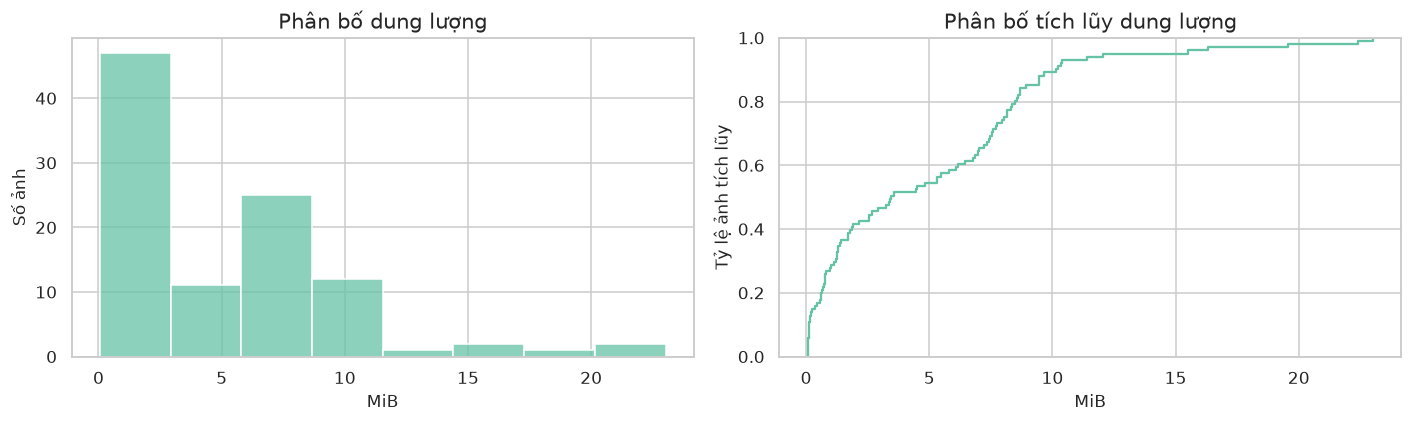

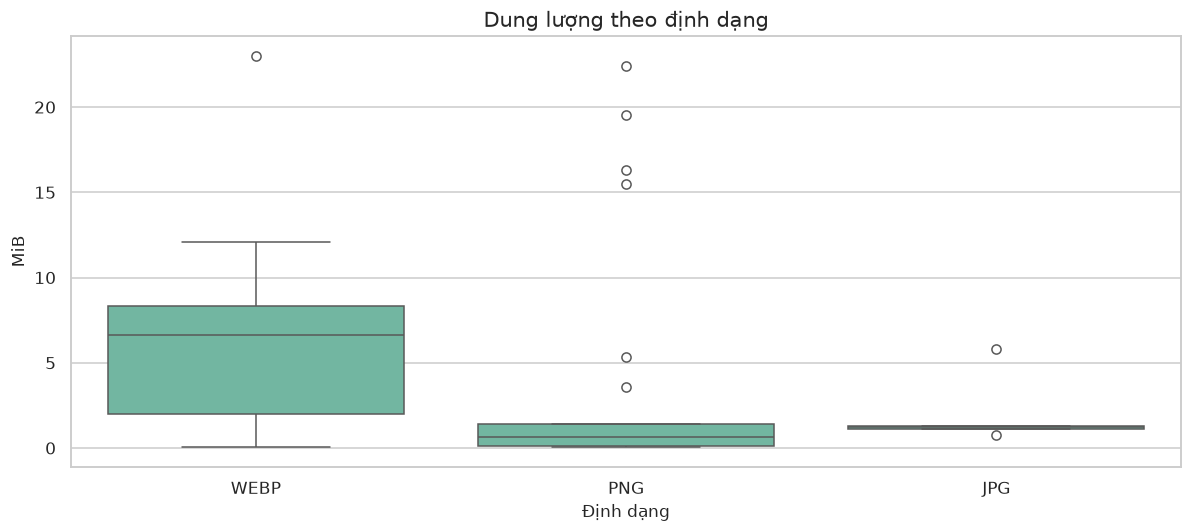

**Phát hiện:** 10 ảnh lớn nhất chiếm **30.1%** dung lượng metadata. Ngưỡng IQR trên log(1+MiB) là **103.38 MiB**, gắn cờ **0 ảnh**. Nên kiểm tra nội dung trước khi cân nhắc nén/chuyển định dạng.

,id,fullname,format,size_mib,megapixels
42,43,pexels-googledeepmind-18069371.webp,WEBP,23.02,28.44
92,93,137840375_p0.png,PNG,22.39,23.73
29,30,2024-01-02_00.13.12.png,PNG,19.56,8.29
28,29,2024-01-01_23.59.23.png,PNG,16.30,8.29
30,31,2024-01-02_00.15.21.png,PNG,15.50,8.29
83,84,pexels-googledeepmind-17485683.webp,WEBP,12.07,28.44
64,65,macos-sonoma-wallpapers-5120x2160-v0-tvdy1kq8h5wb1.webp,WEBP,11.41,11.06
49,50,computing-fields.webp,WEBP,10.38,33.18
44,45,pexels-googledeepmind-18069365.webp,WEBP,10.36,28.44
45,46,pexels-googledeepmind-17485680.webp,WEBP,10.23,28.44


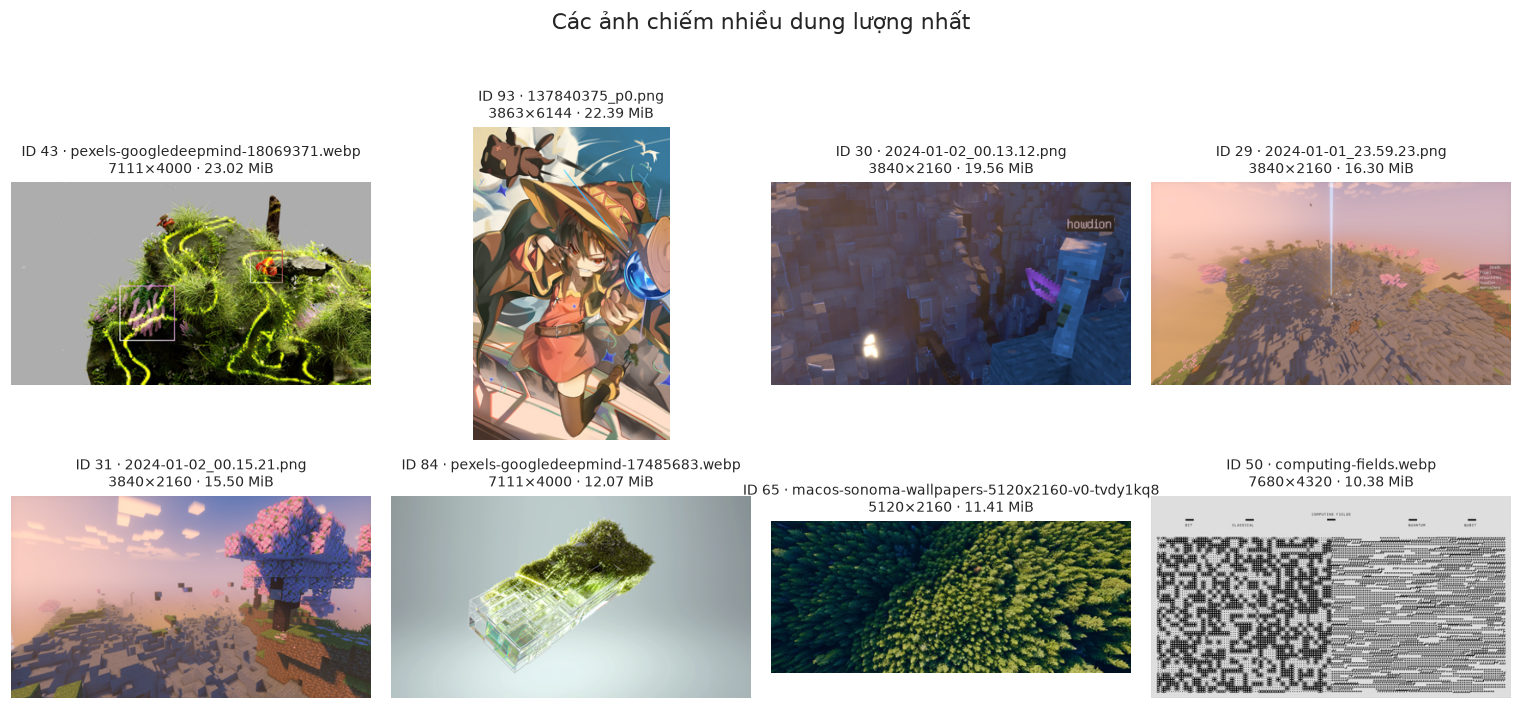

In [ ]:
sizes = df["size_mib"].dropna()
if not sizes.empty:
    display(sizes.describe(percentiles=[.25, .5, .75, .9, .95, .99]).to_frame("MiB").round(3))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    sns.histplot(sizes, bins="auto", ax=axes[0])
    axes[0].set(title="Phân bố dung lượng", xlabel="MiB", ylabel="Số ảnh")
    sns.ecdfplot(sizes, ax=axes[1])
    axes[1].set(title="Phân bố tích lũy dung lượng", xlabel="MiB", ylabel="Tỷ lệ ảnh tích lũy")
    finish(fig)
    fig, ax = plt.subplots()
    sns.boxplot(data=df, x="format", y="size_mib", ax=ax)
    ax.set(title="Dung lượng theo định dạng", xlabel="Định dạng", ylabel="MiB")
    finish(fig)
    log_sizes = np.log1p(sizes)
    q1, q3 = log_sizes.quantile([.25, .75])
    upper_mib = np.expm1(q3 + 1.5*(q3-q1))
    flagged = df.loc[df["size_mib"].gt(upper_mib)].sort_values("size_mib", ascending=False)
    largest = df.dropna(subset=["size_mib"]).nlargest(10, "size_mib")
    top_share = largest["size_mib"].sum()/sizes.sum()*100 if sizes.sum() > 0 else 0
    note(f"**Phát hiện:** {len(largest)} ảnh lớn nhất chiếm **{top_share:.1f}%** dung lượng metadata. "
         f"Ngưỡng IQR trên log(1+MiB) là **{upper_mib:.2f} MiB**, gắn cờ **{len(flagged)} ảnh**. "
         "Nên kiểm tra nội dung trước khi cân nhắc nén/chuyển định dạng.")
    display(largest[["id", "fullname", "format", "size_mib", "megapixels"]].round(2))
    gallery(largest, "Các ảnh chiếm nhiều dung lượng nhất")
else:
    note("Không có dung lượng hợp lệ để phân tích.")

## 3. Kích thước ảnh
**Câu hỏi:** Ảnh có độ phân giải nào, và dung lượng tăng cùng số pixel ra sao?
Màu điểm thể hiện định dạng. Tương quan Spearman mô tả quan hệ đơn điệu, không chứng minh nhân quả.
Không đồng nhất độ phân giải cao với chất lượng ảnh cao.

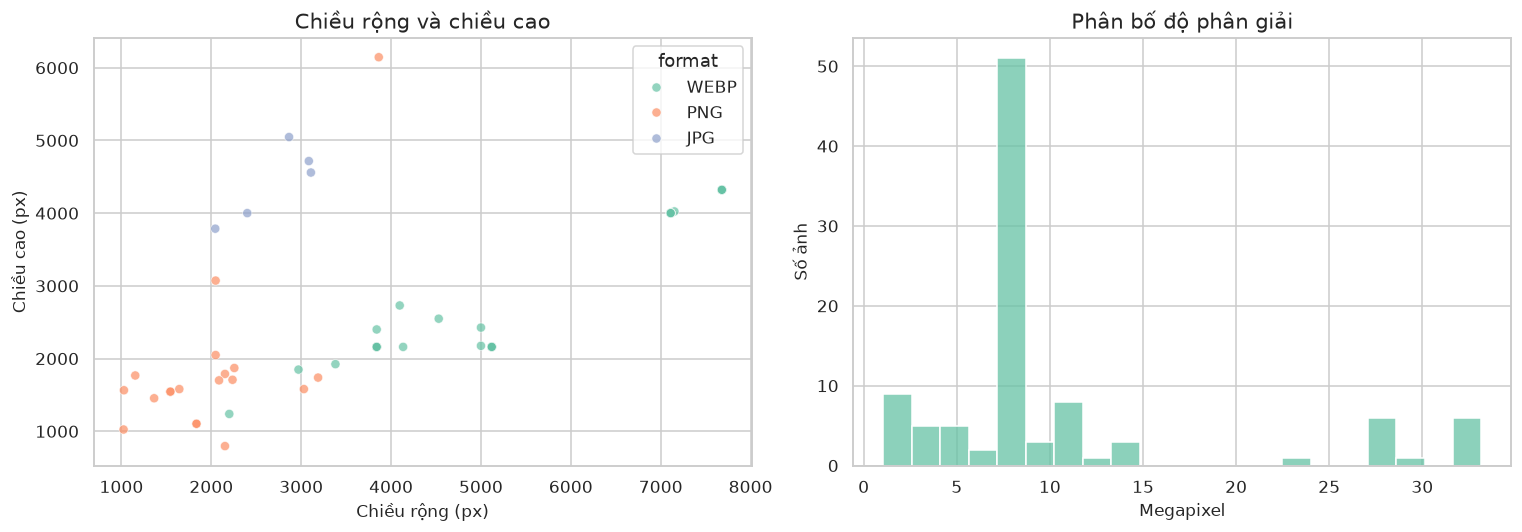

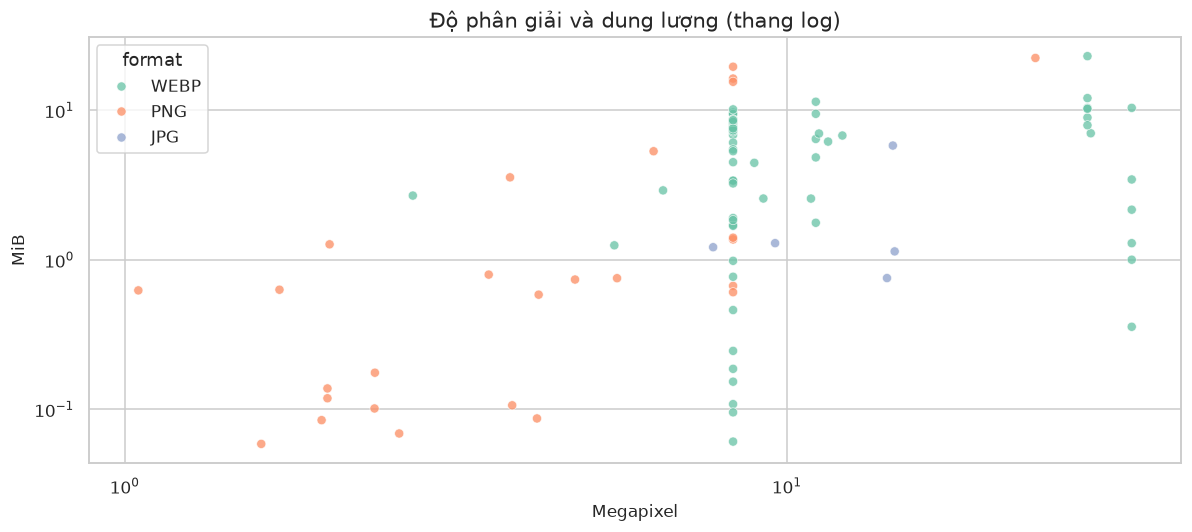

Median độ phân giải: **8.29 MP**. Spearman giữa MP và MiB: **0.457**, trên 101 ảnh.

,,Số ảnh
width,height,
3840,2160,50
7680,4320,6
5120,2160,5
7111,4000,5
1835,1103,2
1024,1024,1
1028,1564,1
1154,1767,1
1364,1454,1


In [ ]:
dims = df.loc[df["valid_dimensions"]].copy()
if not dims.empty:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.scatterplot(data=dims, x="width", y="height", hue="format", alpha=.7, ax=axes[0])
    axes[0].set(title="Chiều rộng và chiều cao", xlabel="Chiều rộng (px)", ylabel="Chiều cao (px)")
    sns.histplot(data=dims, x="megapixels", bins="auto", ax=axes[1])
    axes[1].set(title="Phân bố độ phân giải", xlabel="Megapixel", ylabel="Số ảnh")
    finish(fig)
    positive = dims.loc[dims["size_mib"].gt(0)]
    if not positive.empty:
        fig, ax = plt.subplots()
        sns.scatterplot(data=positive, x="megapixels", y="size_mib", hue="format", alpha=.75, ax=ax)
        ax.set(xscale="log", yscale="log", title="Độ phân giải và dung lượng (thang log)", xlabel="Megapixel", ylabel="MiB")
        finish(fig)
        # Pearson của thứ hạng tương đương Spearman; không cần thêm SciPy.
        corr = positive[["megapixels", "size_mib"]].rank().corr().iloc[0, 1]
        note(f"Median độ phân giải: **{dims['megapixels'].median():.2f} MP**. "
             + (f"Spearman giữa MP và MiB: **{corr:.3f}**, trên {len(positive)} ảnh." if pd.notna(corr)
                else "Không đủ biến thiên để tính tương quan MP–MiB."))
    display(dims.groupby(["width", "height"]).size().nlargest(10).rename("Số ảnh").to_frame())
else:
    note("Không có kích thước hợp lệ.")

## 4. Tỷ lệ khung hình
**Câu hỏi:** Bộ ảnh thiên về ảnh ngang, dọc hay vuông? Các tỷ lệ nào phổ biến?
Tỷ lệ chuẩn được gán khi sai lệch tương đối không vượt 2%; các ảnh còn lại là “Khác”.
Đây là quy tắc phục vụ phân tích, không phải chuẩn nhận diện nội dung ảnh.

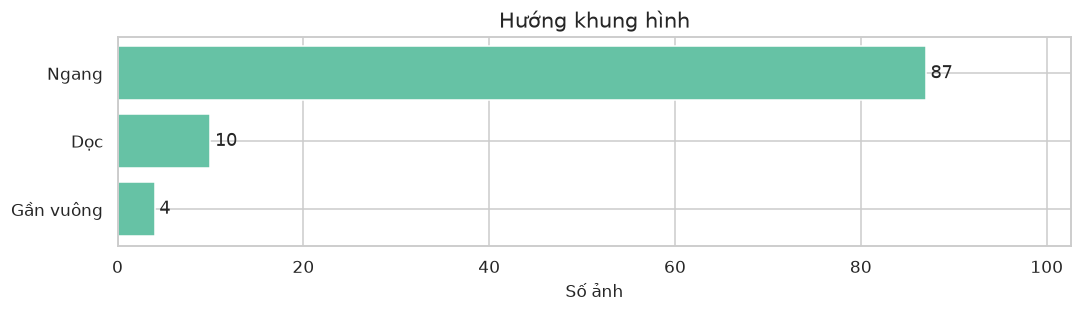

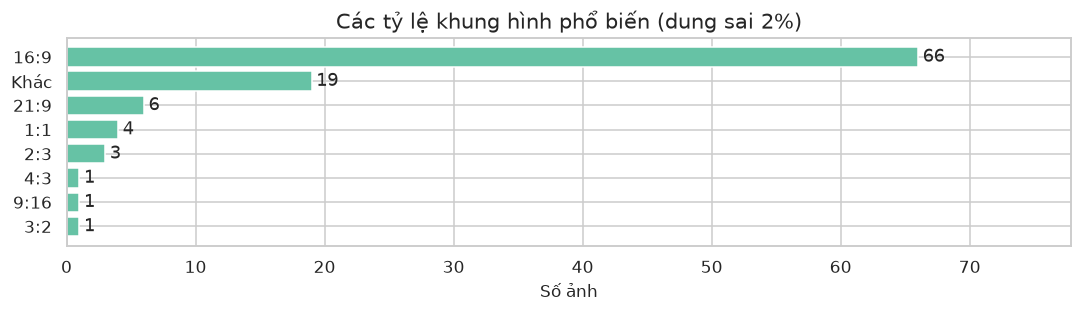

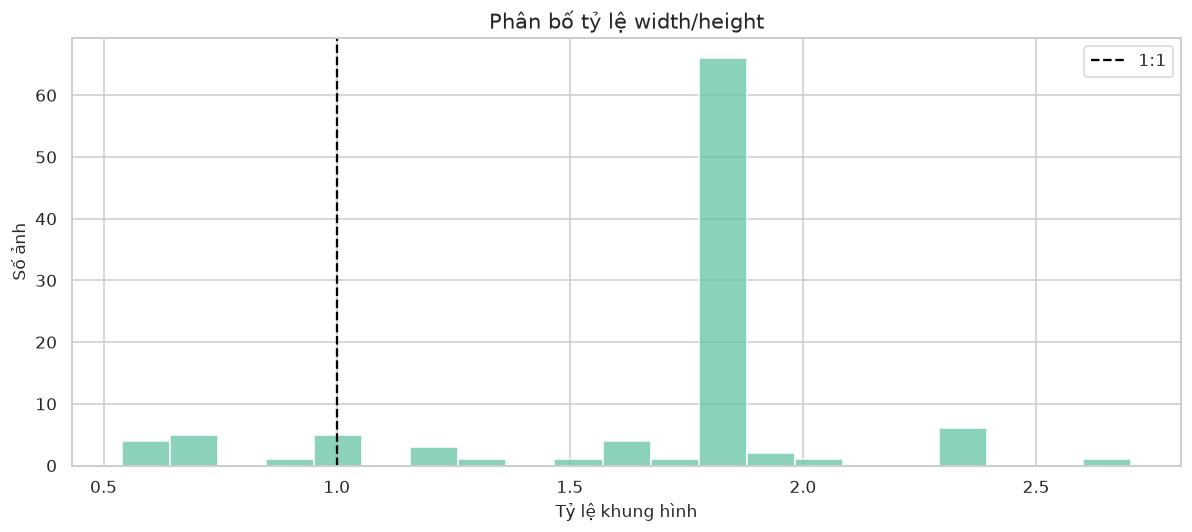

Có **0 ảnh** với tỷ lệ >3 hoặc <1/3; có thể là panorama, banner hoặc ảnh dài, cần xem nội dung.

**Ảnh có tỷ lệ khung hình rất dài:** không có ảnh phù hợp.

In [ ]:
horizontal(df["orientation"].value_counts(), "Hướng khung hình")
standards = {"1:1": 1, "4:3": 4/3, "3:2": 3/2, "16:9": 16/9, "21:9": 21/9,
             "3:4": 3/4, "2:3": 2/3, "9:16": 9/16}
def ratio_label(r):
    if pd.isna(r) or r <= 0:
        return "Không hợp lệ"
    label = min(standards, key=lambda k: abs(r/standards[k]-1))
    return label if abs(r/standards[label]-1) <= .02 else "Khác"
df["ratio_group"] = df["aspect_ratio"].map(ratio_label)
horizontal(df["ratio_group"].value_counts(), "Các tỷ lệ khung hình phổ biến (dung sai 2%)")
ratios = df["aspect_ratio"].dropna()
if not ratios.empty:
    fig, ax = plt.subplots()
    sns.histplot(ratios, bins="auto", ax=ax)
    ax.axvline(1, color="black", linestyle="--", label="1:1")
    ax.set(title="Phân bố tỷ lệ width/height", xlabel="Tỷ lệ khung hình", ylabel="Số ảnh")
    ax.legend()
    finish(fig)
    extreme = df.loc[df["aspect_ratio"].gt(3) | df["aspect_ratio"].lt(1/3)]
    note(f"Có **{len(extreme)} ảnh** với tỷ lệ >3 hoặc <1/3; có thể là panorama, banner hoặc ảnh dài, cần xem nội dung.")
    gallery(extreme, "Ảnh có tỷ lệ khung hình rất dài")

## 5. Màu sắc
**Câu hỏi:** Các màu đại diện của bộ ảnh phân bố thế nào?
Giải mã `0xRRGGBB` từ các cột `color_1…color_4`. Màu đen (`0`) là giá trị hợp lệ.
Thống kê chính dùng **color_1: một màu đại diện/ảnh**, nên không nhân số quan sát lên bốn lần.
Không có trọng số diện tích màu; các cột màu không thể cho biết phần trăm pixel của từng màu.
Nhóm trung tính dùng saturation <0.15, còn lại chia hue thành 10 nhóm; đây là quy ước khám phá.

Có **101/101 ảnh** có color_1 hợp lệ. Độ sáng HLS không phải độ chói cảm nhận hay phơi sáng của ảnh.

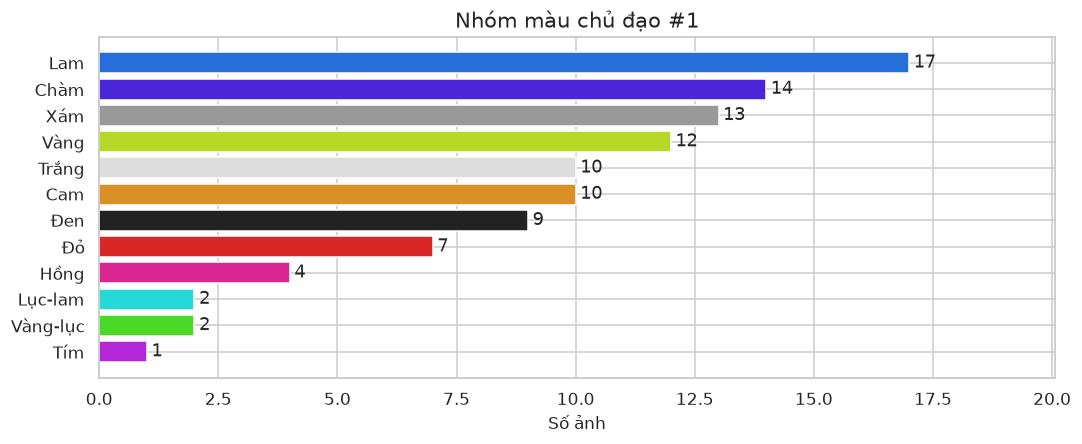

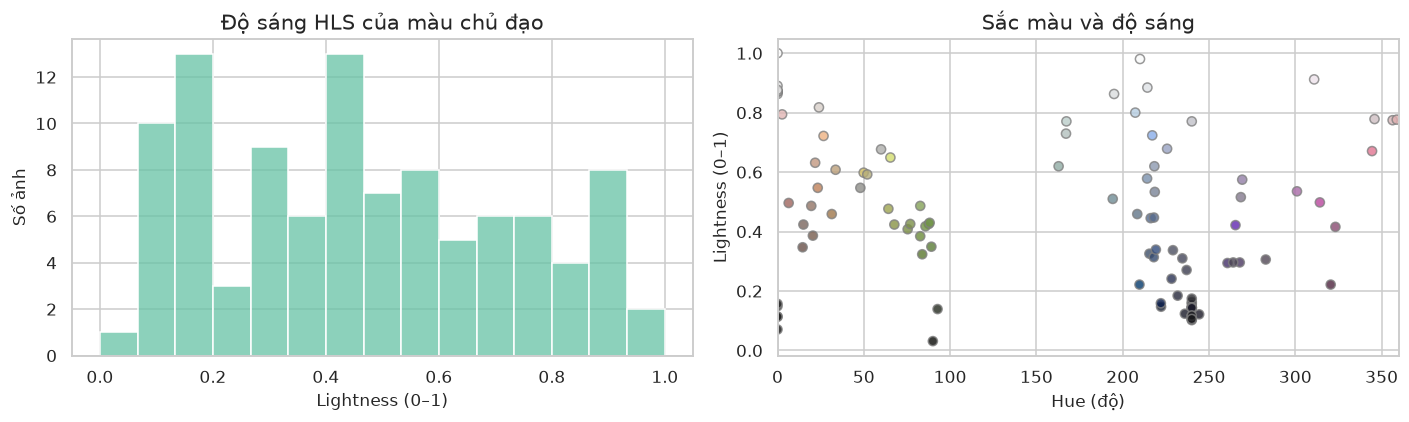

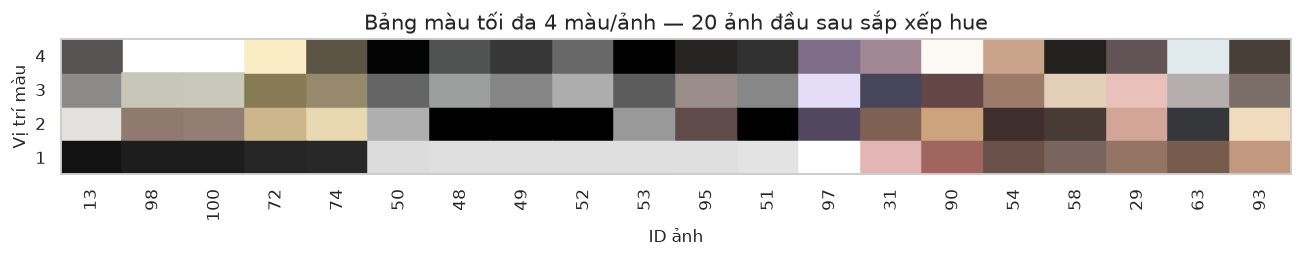

Nhóm màu đại diện phổ biến nhất: **Lam**. Đây là số ảnh có màu đại diện thuộc nhóm, không phải tỷ lệ diện tích màu.

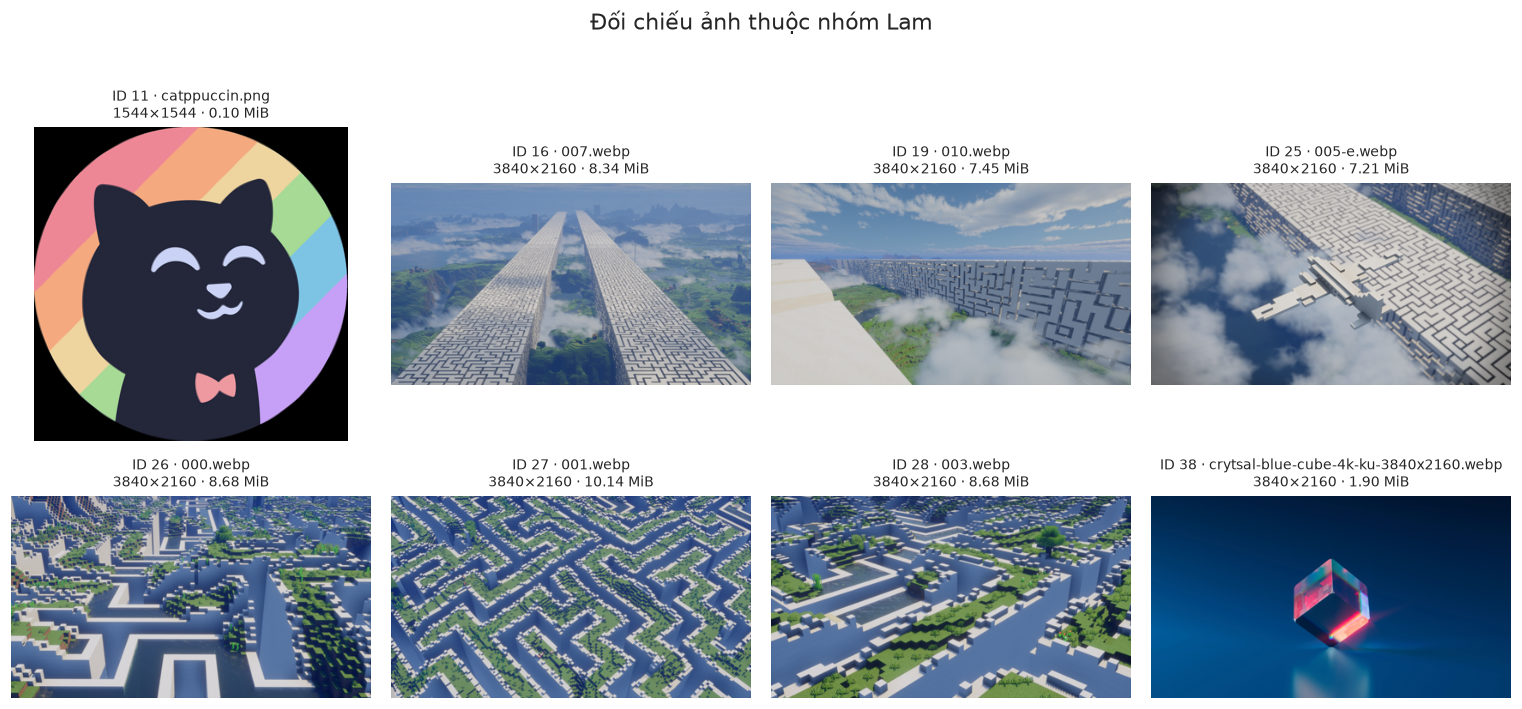

In [ ]:
HUE_NAMES = ["Đỏ", "Cam", "Vàng", "Vàng-lục", "Lục", "Lục-lam", "Lam", "Chàm", "Tím", "Hồng"]
def unpack_color(value):
    try:
        number = float(value)
        if not np.isfinite(number) or not number.is_integer() or not 0 <= number <= 0xFFFFFF:
            return None
        v = int(number)
        return ((v >> 16 & 255)/255, (v >> 8 & 255)/255, (v & 255)/255)
    except (TypeError, ValueError):
        return None
def color_features(value):
    rgb = unpack_color(value)
    if rgb is None:
        return {"hex": None, "hue": np.nan, "lightness": np.nan, "saturation": np.nan, "color_group": None}
    h, l, s = colorsys.rgb_to_hls(*rgb)
    group = ("Đen" if l < .2 else "Trắng" if l > .8 else "Xám") if s < .15 else HUE_NAMES[int((h*360+18)%360//36)]
    return {"hex": to_hex(rgb), "hue": h*360, "lightness": l, "saturation": s, "color_group": group}
color_data = pd.DataFrame(df["color_1"].map(color_features).tolist(), index=df.index)
df = df.join(color_data)
valid_colors = df.dropna(subset=["color_group"])
note(f"Có **{len(valid_colors)}/{len(df)} ảnh** có color_1 hợp lệ. Độ sáng HLS không phải độ chói cảm nhận hay phơi sáng của ảnh.")
if not valid_colors.empty:
    counts = valid_colors["color_group"].value_counts().sort_values()
    palette = {name: colorsys.hls_to_rgb(i/10, .5, .7) for i, name in enumerate(HUE_NAMES)}
    palette.update({"Đen": "#222222", "Xám": "#999999", "Trắng": "#dddddd"})
    horizontal(counts, "Nhóm màu chủ đạo #1", colors=[palette[k] for k in counts.index])
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    sns.histplot(valid_colors["lightness"], bins=15, binrange=(0, 1), ax=axes[0])
    axes[0].set(title="Độ sáng HLS của màu chủ đạo", xlabel="Lightness (0–1)", ylabel="Số ảnh")
    axes[1].scatter(valid_colors["hue"], valid_colors["lightness"], c=valid_colors["hex"], edgecolors="gray", alpha=.8)
    axes[1].set(title="Sắc màu và độ sáng", xlabel="Hue (độ)", ylabel="Lightness (0–1)", xlim=(0, 360))
    finish(fig)
    sample = valid_colors.sort_values(["hue", "lightness"]).head(20)
    fig, ax = plt.subplots(figsize=(12, 2.5))
    for i, (_, row) in enumerate(sample.iterrows()):
        for j, col in enumerate([c for c in ["color_1", "color_2", "color_3", "color_4"] if c in df]):
            rgb = unpack_color(row[col])
            if rgb is not None:
                ax.add_patch(plt.Rectangle((i, j), 1, 1, color=rgb))
    ax.set(xlim=(0, len(sample)), ylim=(0, 4), title="Bảng màu tối đa 4 màu/ảnh — 20 ảnh đầu sau sắp xếp hue",
           xlabel="ID ảnh", ylabel="Vị trí màu")
    ax.set_xticks(np.arange(len(sample))+.5, sample["id"].astype(str), rotation=90)
    ax.set_yticks(np.arange(4)+.5, ["1", "2", "3", "4"])
    ax.grid(False)
    finish(fig)
    leading = valid_colors["color_group"].value_counts().index[0]
    note(f"Nhóm màu đại diện phổ biến nhất: **{leading}**. Đây là số ảnh có màu đại diện thuộc nhóm, không phải tỷ lệ diện tích màu.")
    gallery(valid_colors.loc[valid_colors["color_group"].eq(leading)].head(MAX_GALLERY), f"Đối chiếu ảnh thuộc nhóm {leading}")

## 6. Tags
**Câu hỏi:** Bao nhiêu ảnh được gắn thẻ, nội dung nào xuất hiện nhiều và tags nào thường đi cùng nhau?
Mỗi tag chỉ được đếm một lần trên mỗi ảnh. Heatmap số đếm cho biết tần suất; Jaccard = giao/hợp
giảm ảnh hưởng của độ phổ biến. Cặp tags hiếm có thể có Jaccard cao chỉ vì ít mẫu.
Không có trường nguồn tag trong schema nên không thể xác nhận tag do người dùng hay AI tạo, hoặc coi tag là ground truth.

**75/101 ảnh (74.3%)** có tags; **42 tags khác nhau**. 26 ảnh chưa có tags.

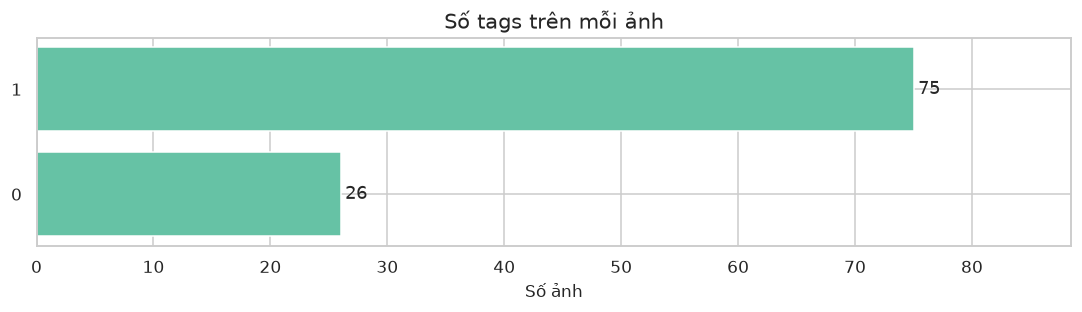

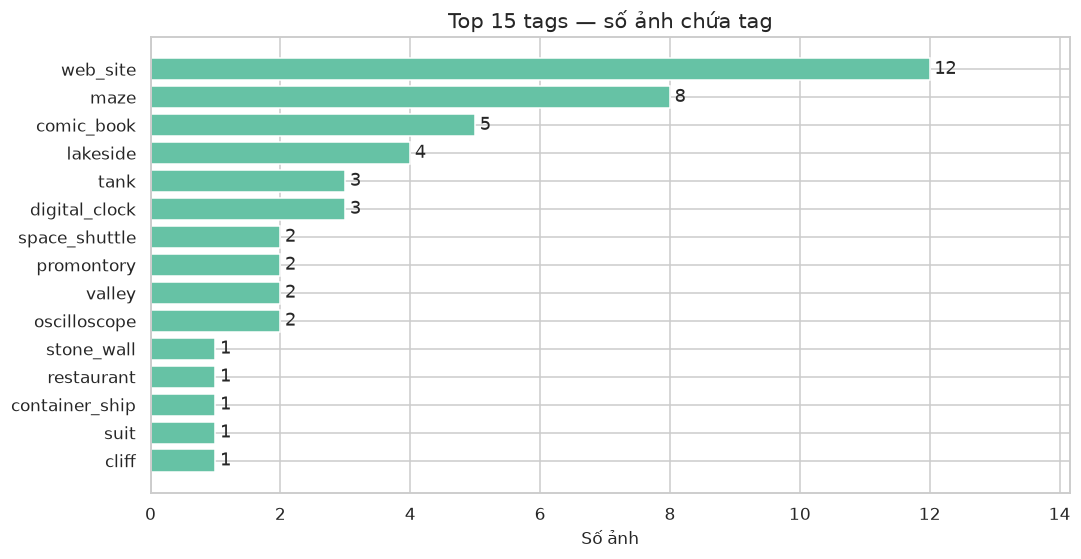

,Số ảnh,% toàn bộ ảnh
web_site,12,11.88
maze,8,7.92
comic_book,5,4.95
lakeside,4,3.96
digital_clock,3,2.97
tank,3,2.97
oscilloscope,2,1.98
promontory,2,1.98
space_shuttle,2,1.98
valley,2,1.98


**Chưa thể phân tích đồng xuất hiện:** mỗi ảnh hiện có tối đa một tag. Không vẽ heatmap toàn số 0 vì không mang thêm thông tin.

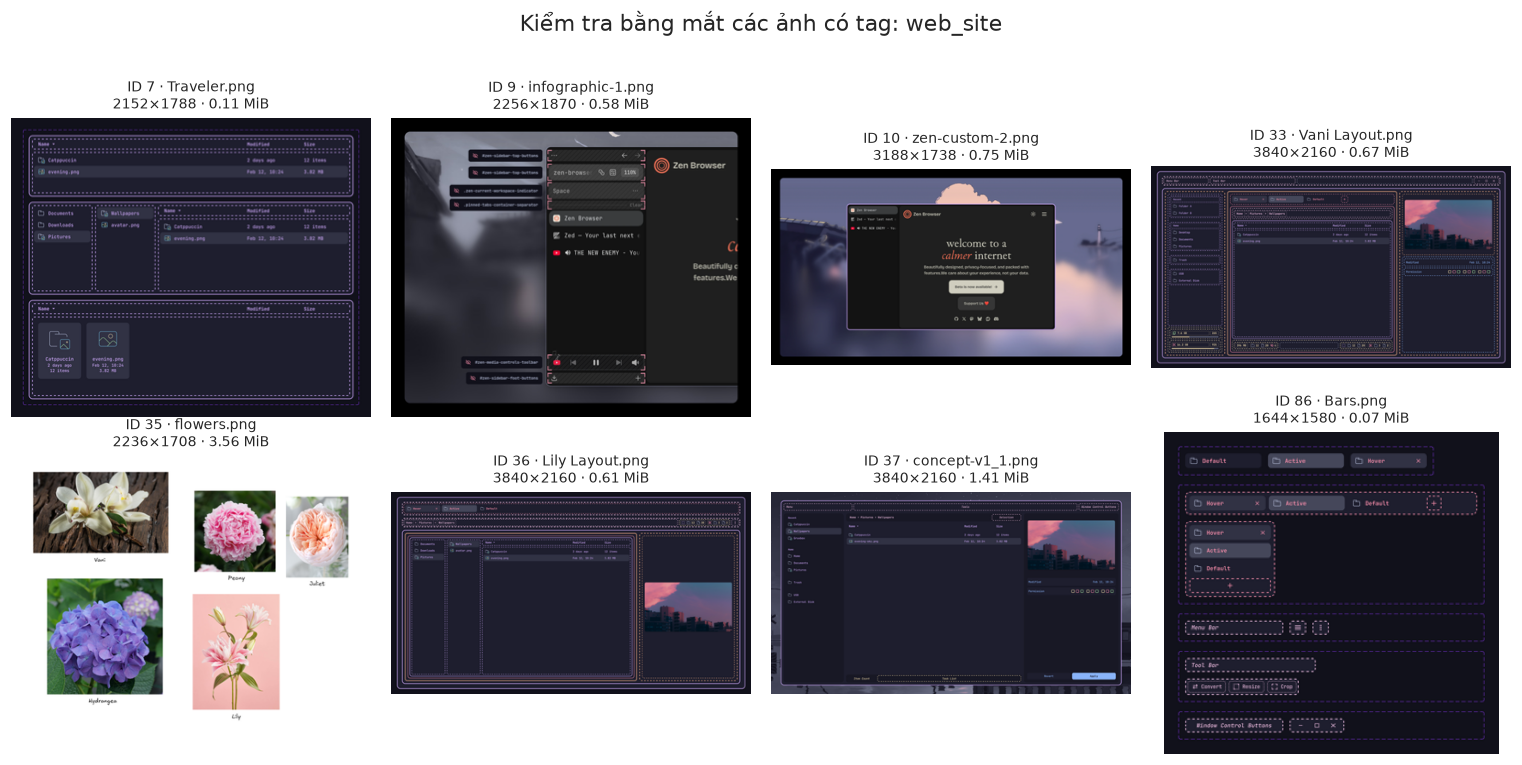

Ảnh mẫu giúp phát hiện nhãn có vẻ chưa phù hợp; muốn đo độ chính xác cần bộ nhãn kiểm chứng riêng.

In [ ]:
tag_counts = Counter(t for tags in df["tag_list"] for t in tags)
note(f"**{df['has_tags'].sum()}/{len(df)} ảnh ({df['has_tags'].mean():.1%})** có tags; "
     f"**{len(tag_counts)} tags khác nhau**. {len(df)-df['has_tags'].sum()} ảnh chưa có tags.")
horizontal(df["tag_count"].value_counts().sort_index(), "Số tags trên mỗi ảnh", "Số ảnh")
if tag_counts:
    tag_freq = pd.Series(tag_counts).sort_values(ascending=False)
    horizontal(tag_freq.head(TOP_N), f"Top {min(TOP_N, len(tag_freq))} tags — số ảnh chứa tag")
    display(pd.DataFrame({"Số ảnh": tag_freq, "% toàn bộ ảnh": tag_freq/len(df)*100}).head(TOP_N).round(2))
    # Đồng xuất hiện chỉ có ý nghĩa nếu thực sự có ảnh nhiều tags.
    if df["tag_count"].ge(2).any():
        top_tags = tag_freq.head(min(12, len(tag_freq))).index.tolist()
        binary = pd.DataFrame({t: df["tag_list"].map(lambda ts: int(t in ts)) for t in top_tags})
        cooccur = binary.T @ binary
        freq = np.diag(cooccur).astype(float)
        union = freq[:, None] + freq[None, :] - cooccur.to_numpy()
        jaccard = np.divide(cooccur.to_numpy(), union, out=np.zeros_like(union), where=union>0)
        mask = np.eye(len(top_tags), dtype=bool)
        fig, axes = plt.subplots(1, 2, figsize=(16, 6))
        sns.heatmap(cooccur, mask=mask, annot=True, fmt="d", cmap="Blues", ax=axes[0])
        sns.heatmap(pd.DataFrame(jaccard, index=top_tags, columns=top_tags), mask=mask,
                    annot=True, fmt=".2f", vmin=0, vmax=1, cmap="YlGnBu", ax=axes[1])
        axes[0].set_title("Đồng xuất hiện tags (số ảnh)")
        axes[1].set_title("Độ tương đồng Jaccard giữa tags")
        finish(fig)
    else:
        note("**Chưa thể phân tích đồng xuất hiện:** mỗi ảnh hiện có tối đa một tag. Không vẽ heatmap toàn số 0 vì không mang thêm thông tin.")
    most_common = tag_freq.index[0]
    gallery(df.loc[df["tag_list"].map(lambda ts: most_common in ts)], f"Kiểm tra bằng mắt các ảnh có tag: {most_common}")
    note("Ảnh mẫu giúp phát hiện nhãn có vẻ chưa phù hợp; muốn đo độ chính xác cần bộ nhãn kiểm chứng riêng.")
else:
    note("Chưa có tags; không thể phân tích nội dung theo tags. Có thể bổ sung tags rồi chạy lại.")

## 7. Rating
**Câu hỏi:** Rating đã được sử dụng đến đâu và có liên hệ gì với metadata?
Chỉ rating 1–5 được dùng để tính điểm trung bình; 0 là chưa đánh giá.
So sánh các nhóm chỉ mang tính mô tả, không kết luận nhân quả hay sở thích chung từ mẫu nhỏ.

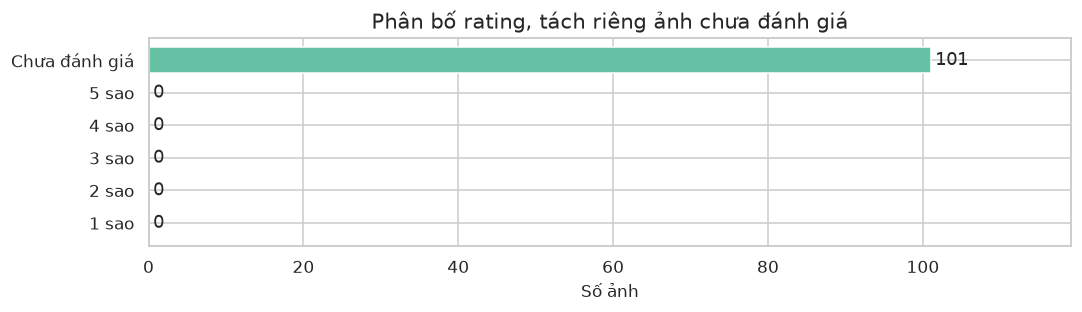

**Chưa có ảnh được đánh giá.** Không tính rating trung bình hoặc tương quan với dung lượng/kích thước. Hãy đánh giá một tập ảnh theo tiêu chí nhất quán rồi chạy lại để mở các phân tích bên dưới.

In [ ]:
rating_counts = df["rating"].value_counts().reindex(range(6), fill_value=0)
rating_counts.index = ["Chưa đánh giá", "1 sao", "2 sao", "3 sao", "4 sao", "5 sao"]
horizontal(rating_counts, "Phân bố rating, tách riêng ảnh chưa đánh giá")
rated = df.loc[df["is_rated"]]
if rated.empty:
    note("**Chưa có ảnh được đánh giá.** Không tính rating trung bình hoặc tương quan với dung lượng/kích thước. "
         "Hãy đánh giá một tập ảnh theo tiêu chí nhất quán rồi chạy lại để mở các phân tích bên dưới.")
else:
    note(f"Có **{len(rated)} ảnh được đánh giá**; rating trung bình trong nhóm này là **{rated['rating'].mean():.2f}/5**.")
    display(rated.groupby("rating").agg(n=("id", "size"), median_mib=("size_mib", "median"),
                                        median_mp=("megapixels", "median")).round(2))
    if rated["rating"].nunique() >= 2:
        fig, axes = plt.subplots(1, 2, figsize=(13, 4))
        sns.boxplot(data=rated, x="rating", y="size_mib", ax=axes[0])
        sns.stripplot(data=rated, x="rating", y="size_mib", color="black", alpha=.4, ax=axes[0])
        sns.boxplot(data=rated, x="rating", y="megapixels", ax=axes[1])
        axes[0].set(title="Dung lượng theo rating", ylabel="MiB", xlabel="Rating")
        axes[1].set(title="Độ phân giải theo rating", ylabel="MP", xlabel="Rating")
        finish(fig)
    else:
        note("Chỉ có một mức rating; chưa thể so sánh giữa các mức.")

## 8. Thời gian
**Câu hỏi:** Metadata thời gian của file phân bố thế nào, có dấu hiệu được tạo đồng loạt khi sao chép không?
Chuyển epoch milliseconds từ UTC sang múi giờ Việt Nam trước khi nhóm ngày/giờ.
Biểu đồ theo tháng bao gồm cả tháng không có ảnh trong khoảng quan sát.
Heatmap phản ánh timestamp file, **không chứng minh hành vi chụp ảnh của người dùng**.

,Trường,Hợp lệ,Số ngày khác nhau,Sớm nhất,Muộn nhất,Trong tương lai
0,created,101,3,2026-09-03 10:08:25.250000+07:00,2026-11-09 12:59:51.680000+07:00,0
1,modified,101,9,2025-07-16 19:17:22+07:00,2026-10-18 16:33:38+07:00,0


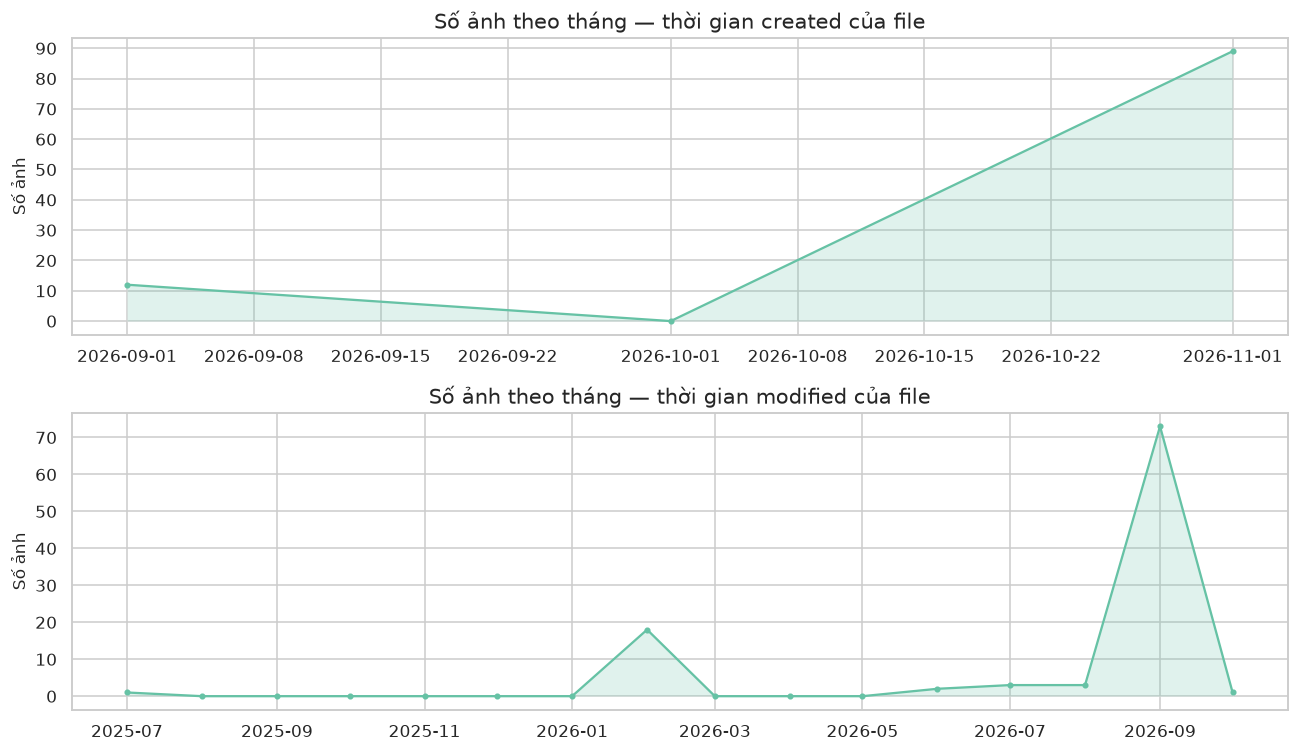

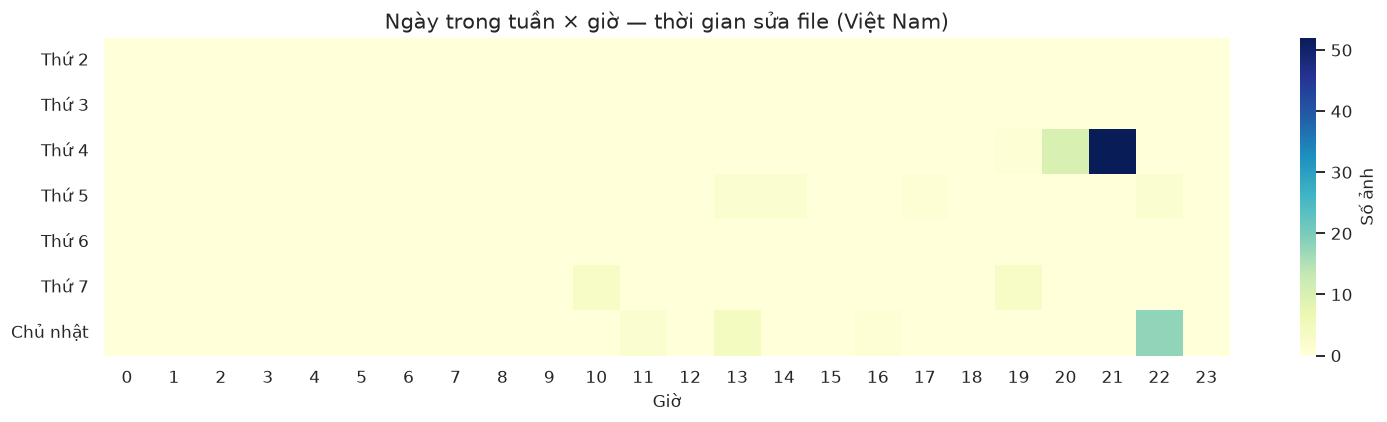

**88.1%** thời gian tạo file tập trung vào cùng một ngày phổ biến nhất. Nếu tỷ lệ này cao, có thể do sao chép/khôi phục file; cần EXIF hoặc nhật ký nhập để kiểm chứng.

Có **94 ảnh** với thời gian sửa sớm hơn thời gian tạo file. Điều này có thể xảy ra khi sao chép giữ nguyên thời gian sửa, không mặc định là dữ liệu sai.

In [ ]:
time_rows = []
for col in ["created", "modified"]:
    dates = df[col+"_datetime"].dropna()
    time_rows.append({"Trường": col, "Hợp lệ": len(dates), "Số ngày khác nhau": dates.dt.date.nunique(),
                      "Sớm nhất": dates.min(), "Muộn nhất": dates.max(), "Trong tương lai": dates.gt(RUN_AT).sum()})
display(pd.DataFrame(time_rows))
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, col in zip(axes, ["created", "modified"]):
    dates = df[col+"_datetime"].dropna()
    if dates.empty:
        ax.text(.5, .5, "Không có thời gian hợp lệ", ha="center")
        ax.set_title(col)
        continue
    monthly = pd.Series(1, index=pd.DatetimeIndex(dates)).resample("MS").sum()
    ax.plot(monthly.index, monthly.values, marker="o", markersize=3)
    ax.fill_between(monthly.index, monthly.values, alpha=.2)
    ax.set(title=f"Số ảnh theo tháng — thời gian {col} của file", ylabel="Số ảnh")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
finish(fig)

dates = df["modified_datetime"].dropna()
if not dates.empty:
    calendar = pd.crosstab(dates.dt.dayofweek, dates.dt.hour).reindex(index=range(7), columns=range(24), fill_value=0)
    calendar.index = ["Thứ 2", "Thứ 3", "Thứ 4", "Thứ 5", "Thứ 6", "Thứ 7", "Chủ nhật"]
    fig, ax = plt.subplots(figsize=(14, 4))
    sns.heatmap(calendar, cmap="YlGnBu", ax=ax, cbar_kws={"label": "Số ảnh"})
    ax.set(title="Ngày trong tuần × giờ — thời gian sửa file (Việt Nam)", xlabel="Giờ", ylabel="")
    finish(fig)
created = df["created_datetime"].dropna()
if not created.empty:
    daily_share = created.dt.date.value_counts(normalize=True).iloc[0]
    note(f"**{daily_share:.1%}** thời gian tạo file tập trung vào cùng một ngày phổ biến nhất. "
         "Nếu tỷ lệ này cao, có thể do sao chép/khôi phục file; cần EXIF hoặc nhật ký nhập để kiểm chứng.")
reverse_time = (df["modified_datetime"] < df["created_datetime"]).sum()
note(f"Có **{reverse_time} ảnh** với thời gian sửa sớm hơn thời gian tạo file. "
     "Điều này có thể xảy ra khi sao chép giữ nguyên thời gian sửa, không mặc định là dữ liệu sai.")

## Kết luận và hướng sử dụng kết quả
Các phát hiện dưới đây được tính lại từ dataset mỗi lần Run All, không dùng số liệu giả định.
Đây là EDA mô tả của một Collection, không đại diện cho mọi bộ ảnh hay mọi người dùng.

In [ ]:
findings = [
    {"Chủ đề": "Quy mô", "Phát hiện": f"{len(df)} ảnh; {df['size_mib'].sum():.2f} MiB theo metadata",
     "Hành động": "Đối chiếu dung lượng thực tế; không cộng thumbnail như ảnh gốc"},
    {"Chủ đề": "Tags", "Phát hiện": f"{(~df['has_tags']).sum()} ảnh chưa có tags; {len(tag_counts)} tags khác nhau",
     "Hành động": "Ưu tiên bổ sung/kiểm chứng tags trước khi phân tích nội dung sâu"},
    {"Chủ đề": "Rating", "Phát hiện": f"{df['is_rated'].sum()} ảnh được đánh giá từ 1–5",
     "Hành động": "Thu thập rating có tiêu chí; không diễn giải 0 là chất lượng thấp"},
    {"Chủ đề": "Tính toàn vẹn", "Phát hiện": f"{(~df['image_exists']).sum()} file ảnh và {(~df['thumbnail_exists']).sum()} thumbnail thiếu",
     "Hành động": "Xử lý các liên kết thiếu trước khi demo"},
    {"Chủ đề": "Màu sắc", "Phát hiện": f"{len(valid_colors)} ảnh có màu đại diện hợp lệ",
     "Hành động": "Dùng để lọc/khám phá; cần phân tích pixel nếu muốn đo diện tích hoặc phơi sáng"},
]
if embedding_audit_ok:
    findings.append({"Chủ đề": "Embeddings", "Phát hiện": f"{df['has_embedding_record'].sum()}/{len(df)} ảnh khớp ID Chroma",
                     "Hành động": "Cần bộ truy vấn và nhãn liên quan để đánh giá semantic search"})
display(pd.DataFrame(findings))
note("**Giới hạn cần ghi trong báo cáo:** tags chưa có thông tin nguồn; rating có thể thiếu; timestamp là của file; "
     "màu không có trọng số diện tích; chưa kiểm chứng mọi ảnh có giải mã được hay mọi vector có hợp lệ. "
     "Các ảnh trong gallery được chọn có chủ đích để kiểm tra, không phải mẫu đại diện ngẫu nhiên.")

,Chủ đề,Phát hiện,Hành động
0,Quy mô,101 ảnh; 502.99 MiB theo metadata,Đối chiếu dung lượng thực tế; không cộng thumbnail như ảnh gốc
1,Tags,26 ảnh chưa có tags; 42 tags khác nhau,Ưu tiên bổ sung/kiểm chứng tags trước khi phân tích nội dung sâu
2,Rating,0 ảnh được đánh giá từ 1–5,Thu thập rating có tiêu chí; không diễn giải 0 là chất lượng thấp
3,Tính toàn vẹn,0 file ảnh và 0 thumbnail thiếu,Xử lý các liên kết thiếu trước khi demo
4,Màu sắc,101 ảnh có màu đại diện hợp lệ,Dùng để lọc/khám phá; cần phân tích pixel nếu muốn đo diện tích ho...
5,Embeddings,101/101 ảnh khớp ID Chroma,Cần bộ truy vấn và nhãn liên quan để đánh giá semantic search


**Giới hạn cần ghi trong báo cáo:** tags chưa có thông tin nguồn; rating có thể thiếu; timestamp là của file; màu không có trọng số diện tích; chưa kiểm chứng mọi ảnh có giải mã được hay mọi vector có hợp lệ. Các ảnh trong gallery được chọn có chủ đích để kiểm tra, không phải mẫu đại diện ngẫu nhiên.